# Duplicate-Record Matching with Human Review

### Problem
A product catalog has near-duplicate records (spelling mistakes, different casing, different formatting). A matching tool should suggest duplicate pairs but must NOT silently merge different products, for example the same juice in 500 ml and 1 L.

### What I build
1. 500 fictional product records with known duplicates, size variants and look-alike names
2. A blocking step to cut the number of pairs, and a report of duplicates the blocking missed
3. String similarity (TF-IDF characters + difflib) with a hard rule: different normalised sizes are never a match
4. Threshold sensitivity table (precision, recall, review workload)
5. A reversible review log in SQLite and an exported mapping (source records are never overwritten)
6. Acceptance tests

### How to run
Run all cells. All data is generated here with seed 42. Needs: pandas, numpy, scikit-learn, matplotlib.

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib

## Step 1: Imports

In [2]:
import random
import sqlite3
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

random.seed(42)
np.random.seed(42)
print("ready")

ready


## Step 2: Make 500 fictional product records
- 380 base products
- 70 true duplicates of base products (typos, casing, extra spaces, size written differently like `1L` vs `1000 ml`)
- 50 size variants (same name, different size). These are NOT duplicates
The generator remembers the true groups, so I can score the matching later.

In [3]:
brands = ["Sunfield", "GreenLeaf", "Blue Mountain", "Kiro", "Pure Drop", "Daily Fresh", "Orchid", "Tastiva", "Nova", "Maple Hill",
          "Zesta", "Harvest Co", "Aqualine", "Bright Day", "Nutri Peak"]
items = ["Orange Juice", "Apple Juice", "Whole Milk", "Oat Milk", "Basmati Rice", "Brown Bread", "Peanut Butter", "Tomato Ketchup",
         "Olive Oil", "Green Tea", "Instant Coffee", "Corn Flakes", "Dish Soap", "Hand Wash", "Shampoo", "Body Lotion",
         "Toothpaste", "Cooking Oil", "Wheat Flour", "Sugar", "Salt", "Dark Chocolate", "Potato Chips", "Soda Water"]
sizes = [(250, "ml"), (500, "ml"), (1, "l"), (2, "l"), (100, "g"), (200, "g"), (500, "g"), (1, "kg"), (2, "kg")]
categories = {"Orange Juice": "drinks", "Apple Juice": "drinks", "Whole Milk": "dairy", "Oat Milk": "dairy", "Basmati Rice": "grocery",
              "Brown Bread": "bakery", "Peanut Butter": "grocery", "Tomato Ketchup": "grocery", "Olive Oil": "grocery",
              "Green Tea": "drinks", "Instant Coffee": "drinks", "Corn Flakes": "grocery", "Dish Soap": "home", "Hand Wash": "home",
              "Shampoo": "personal", "Body Lotion": "personal", "Toothpaste": "personal", "Cooking Oil": "grocery",
              "Wheat Flour": "grocery", "Sugar": "grocery", "Salt": "grocery", "Dark Chocolate": "snacks",
              "Potato Chips": "snacks", "Soda Water": "drinks"}


def typo(text):
    if len(text) < 5:
        return text
    pos = random.randint(1, len(text) - 2)
    kind = random.choice(["drop", "swap", "double"])
    if kind == "drop":
        return text[:pos] + text[pos + 1:]
    if kind == "swap":
        return text[:pos] + text[pos + 1] + text[pos] + text[pos + 2:]
    return text[:pos] + text[pos] + text[pos:]


def size_text(v, u, style):
    if style == 0:
        return str(v) + " " + u
    if style == 1:
        return str(v) + u.upper()
    # write in another unit when possible
    if u == "l":
        return str(v * 1000) + " ml"
    if u == "kg":
        return str(v * 1000) + " g"
    return str(v) + u


records = []
rid = 0
true_group = {}

# base products (unique combos)
combos = set()
while len(combos) < 380:
    combos.add((random.choice(brands), random.choice(items), random.choice(sizes)))
combos = sorted(combos)
random.shuffle(combos)

for g, (b, it, sz) in enumerate(combos):
    records.append({"rec_id": rid, "brand": b, "name": it, "size_text": size_text(sz[0], sz[1], 0), "category": categories[it], "kind": "base"})
    true_group[rid] = g
    rid += 1

# true duplicates
for _ in range(70):
    g = random.randint(0, 379)
    b, it, sz = combos[g]
    b2 = typo(b) if random.random() < 0.3 else b
    it2 = typo(it) if random.random() < 0.6 else it
    if random.random() < 0.4:
        it2 = it2.upper()
    records.append({"rec_id": rid, "brand": b2, "name": "  " + it2 + " ", "size_text": size_text(sz[0], sz[1], random.randint(1, 2)),
                    "category": categories[it], "kind": "duplicate"})
    true_group[rid] = g
    rid += 1

# size variants: same brand + name but a different size, own group each
all_groups = 380
for _ in range(50):
    g = random.randint(0, 379)
    b, it, sz = combos[g]
    other = random.choice([s for s in sizes if s != sz])
    records.append({"rec_id": rid, "brand": b, "name": it, "size_text": size_text(other[0], other[1], 0),
                    "category": categories[it], "kind": "size_variant"})
    true_group[rid] = all_groups
    all_groups += 1
    rid += 1

df = pd.DataFrame(records)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print(df.shape)
print(df["kind"].value_counts())
df.head(8)

(500, 6)
kind
base            380
duplicate        70
size_variant     50
Name: count, dtype: int64


,rec_id,brand,name,size_text,category,kind
0,361,Sunfield,Shampoo,500 ml,personal,base
1,73,Nova,Hand Wash,2 l,home,base
2,374,Zesta,Hand Wash,100 g,home,base
3,155,Aqualine,Body Lotion,1 kg,personal,base
4,104,Daily Fresh,Tomato Ketchup,500 ml,grocery,base
5,394,GreenLeaf,Potato Chps,250ml,snacks,duplicate
6,377,Harvest Co,Instant Coffee,100 g,drinks,base
7,124,Orchid,Sugar,1 kg,grocery,base


## Step 3: Define what "duplicate" means
- Same product = same brand (allowing a typo), same item name (allowing a typo) and same **normalised size**
- Different size = different product (a variant), even if the name is identical
- Missing info is kept separate from "agree": if a size is missing it is marked `unknown`, not equal

Below I clean the text and turn sizes into one base unit (ml or g).

In [4]:
def clean_text(x):
    return " ".join(str(x).lower().split())


def size_to_base(text):
    t = text.lower().replace(" ", "")
    num = ""
    unit = ""
    for ch in t:
        if ch.isdigit() or ch == ".":
            num += ch
        else:
            unit += ch
    if num == "":
        return "unknown"
    v = float(num)
    if unit == "l":
        return str(int(v * 1000)) + "ml"
    if unit == "ml":
        return str(int(v)) + "ml"
    if unit == "kg":
        return str(int(v * 1000)) + "g"
    if unit == "g":
        return str(int(v)) + "g"
    return "unknown"


df["brand_c"] = df["brand"].apply(clean_text)
df["name_c"] = df["name"].apply(clean_text)
df["size_base"] = df["size_text"].apply(size_to_base)
df["text"] = df["brand_c"] + " " + df["name_c"]
df["group"] = df["rec_id"].map(true_group)
print(df[["rec_id", "brand_c", "name_c", "size_text", "size_base"]].head(6))
print("unknown sizes:", (df["size_base"] == "unknown").sum())

   rec_id      brand_c          name_c size_text size_base
0     361     sunfield         shampoo    500 ml     500ml
1      73         nova       hand wash       2 l    2000ml
2     374        zesta       hand wash     100 g      100g
3     155     aqualine     body lotion      1 kg     1000g
4     104  daily fresh  tomato ketchup    500 ml     500ml
5     394    greenleaf     potato chps     250ml     250ml
unknown sizes: 0


## Step 4: Known true pairs and blocking
Comparing every record with every other record is 124,750 pairs. Blocking makes this smaller. I try two simple rules and report how many true duplicates each one misses.
- Rule A: same category + same first 3 letters of brand
- Rule B: same category + same first 4 letters of the item name
- Union of A and B

In [5]:
n = len(df)
group_arr = df["group"].values

true_pairs = set()
by_group = df.groupby("group")["rec_id"].apply(list)
for g, ids in by_group.items():
    if len(ids) > 1:
        for i in range(len(ids)):
            for j in range(i + 1, len(ids)):
                true_pairs.add((min(ids[i], ids[j]), max(ids[i], ids[j])))
print("true duplicate pairs in data:", len(true_pairs))

idx_of = {r: i for i, r in enumerate(df["rec_id"])}


def make_blocks(keyfunc):
    blocks = {}
    for i in range(n):
        k = keyfunc(df.iloc[i])
        blocks.setdefault(k, []).append(i)
    pairs = set()
    for k, members in blocks.items():
        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                ra = df.iloc[members[a]]["rec_id"]
                rb = df.iloc[members[b]]["rec_id"]
                pairs.add((min(ra, rb), max(ra, rb)))
    return pairs


pairs_a = make_blocks(lambda r: (r["category"], r["brand_c"][:3]))
pairs_b = make_blocks(lambda r: (r["category"], r["name_c"].replace(" ", "")[:4]))
pairs_u = pairs_a | pairs_b
total_pairs = n * (n - 1) // 2

block_rows = []
for nm, p in [("A brand3", pairs_a), ("B name4", pairs_b), ("A or B", pairs_u)]:
    found = len(p & true_pairs)
    block_rows.append({"rule": nm, "candidate_pairs": len(p), "reduction_%": round(100 * (1 - len(p) / total_pairs), 1),
                       "true_pairs_kept": found, "blocking_recall": round(found / len(true_pairs), 3)})
block_df = pd.DataFrame(block_rows)
print(block_df)

missed = sorted(true_pairs - pairs_u)
print("true duplicates missed by rule A alone:", len(true_pairs - pairs_a))
print("true duplicates missed by rule B alone:", len(true_pairs - pairs_b))
print("true duplicates missed by A or B together:", len(missed))

true duplicate pairs in data: 76
       rule  candidate_pairs  reduction_%  true_pairs_kept  blocking_recall
0  A brand3             1915         98.5               69            0.908
1   B name4             5117         95.9               70            0.921
2    A or B             6607         94.7               76            1.000
true duplicates missed by rule A alone: 7
true duplicates missed by rule B alone: 6
true duplicates missed by A or B together: 0


In [6]:
# separate report of what blocking missed (never hide these)
miss_rows = []
for a, b in missed:
    ra = df[df["rec_id"] == a].iloc[0]
    rb = df[df["rec_id"] == b].iloc[0]
    miss_rows.append({"rec_a": a, "name_a": ra["brand"] + " | " + ra["name"].strip(), "rec_b": b, "name_b": rb["brand"] + " | " + rb["name"].strip()})
missed_report = pd.DataFrame(miss_rows)
print(missed_report.head(10))
missed_report.to_csv("blocking_missed_pairs.csv", index=False)

Empty DataFrame
Columns: []
Index: []


## Step 5: Score the candidate pairs
Two simple scores on `brand + name`:
1. TF-IDF on character 3-grams, cosine similarity
2. `difflib` ratio (plain string match)

Then the size rule: if both sizes are known and different, the pair is a **variant**, never a match.

In [7]:
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3))
X = vec.fit_transform(df["text"])

cand = sorted(pairs_u)
rows = []
for a, b in cand:
    ia, ib = idx_of[a], idx_of[b]
    s_tfidf = float(cosine_similarity(X[ia], X[ib])[0, 0])
    s_diff = difflib.SequenceMatcher(None, df.iloc[ia]["text"], df.iloc[ib]["text"]).ratio()
    sa, sb = df.iloc[ia]["size_base"], df.iloc[ib]["size_base"]
    if sa == "unknown" or sb == "unknown":
        size_flag = "unknown"
    elif sa == sb:
        size_flag = "same"
    else:
        size_flag = "different"
    rows.append({"rec_a": a, "rec_b": b, "tfidf": s_tfidf, "difflib": s_diff, "size_flag": size_flag,
                 "is_true": (a, b) in true_pairs})

scored = pd.DataFrame(rows)
scored["score"] = (scored["tfidf"] + scored["difflib"]) / 2
print(scored.shape)
print(scored.groupby("size_flag").size())
scored.sort_values("score", ascending=False).head(8)

(6607, 7)
size_flag
different    5796
same          811
dtype: int64


,rec_a,rec_b,tfidf,difflib,size_flag,is_true,score
1251,48,235,1.0,1.0,different,False,1.0
5419,285,459,1.0,1.0,different,False,1.0
3216,138,194,1.0,1.0,different,False,1.0
5409,285,355,1.0,1.0,different,False,1.0
2392,98,126,1.0,1.0,different,False,1.0
6103,355,459,1.0,1.0,different,False,1.0
3929,179,395,1.0,1.0,same,True,1.0
4302,203,450,1.0,1.0,different,False,1.0


## Step 6: Threshold sensitivity
Decision rule for a pair:
- size different -> `variant` (never merged)
- score >= HIGH -> `suggest_match`
- LOW <= score < HIGH -> `uncertain` (goes to human review)
- below LOW -> `no_match`

Precision/recall are for pairs the tool suggests as a match. Review workload is how many pairs a human has to look at.

   low  high  suggested  precision  recall_auto  recall_with_review  \
0  0.5  0.90         39      0.872        0.447               1.000   
1  0.6  0.85         53      0.906        0.632               1.000   
2  0.6  0.80         73      0.849        0.816               1.000   
3  0.7  0.80         73      0.849        0.816               0.987   
4  0.7  0.90         39      0.872        0.447               0.987   

   review_workload  
0              613  
1              388  
2              368  
3              114  
4              148  


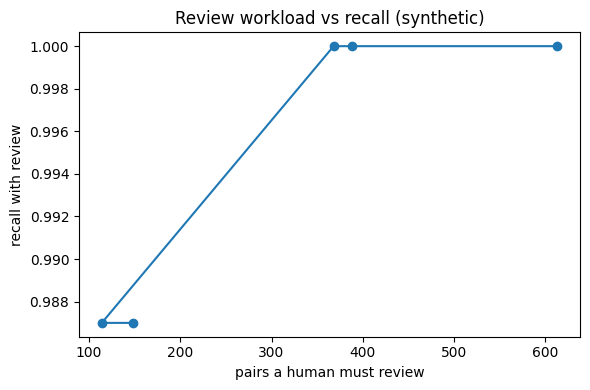

In [8]:
def decide(row, low, high):
    if row["size_flag"] == "different":
        return "variant"
    if row["score"] >= high:
        return "suggest_match"
    if row["score"] >= low:
        return "uncertain"
    return "no_match"


sens = []
for low, high in [(0.5, 0.9), (0.6, 0.85), (0.6, 0.8), (0.7, 0.8), (0.7, 0.9)]:
    d = scored.apply(lambda r: decide(r, low, high), axis=1)
    sug = scored[d == "suggest_match"]
    tp = int(sug["is_true"].sum())
    prec = tp / len(sug) if len(sug) > 0 else 0
    # recall counts uncertain too since a human can accept them
    rec_auto = tp / len(true_pairs)
    rec_review = int(scored[d.isin(["suggest_match", "uncertain"])]["is_true"].sum()) / len(true_pairs)
    sens.append({"low": low, "high": high, "suggested": len(sug), "precision": round(prec, 3),
                 "recall_auto": round(rec_auto, 3), "recall_with_review": round(rec_review, 3),
                 "review_workload": int((d == "uncertain").sum())})
sens_df = pd.DataFrame(sens)
print(sens_df)

plt.figure(figsize=(6, 4))
plt.plot(sens_df["review_workload"], sens_df["recall_with_review"], "o-")
plt.xlabel("pairs a human must review")
plt.ylabel("recall with review")
plt.title("Review workload vs recall (synthetic)")
plt.tight_layout()
plt.savefig("threshold_sensitivity.png")
plt.show()

## Step 7: Reversible review log in SQLite
Every decision (accepted, rejected, uncertain) is stored with who/why/when. The source table is never changed. The mapping is built from the log, so undo is just writing a new row.

In [9]:
LOW, HIGH = 0.6, 0.85
scored["decision"] = scored.apply(lambda r: decide(r, LOW, HIGH), axis=1)

con = sqlite3.connect(":memory:")
df[["rec_id", "brand", "name", "size_text", "category"]].to_sql("source_records", con, index=False)
con.execute("create table review_log (id integer primary key autoincrement, rec_a int, rec_b int, status text, reason text, step int)")
con.execute("create table review_state (rec_a int, rec_b int, status text)")

# put every non-trivial pair in the log as the tool's first opinion
step = 0
for r in scored[scored["decision"].isin(["suggest_match", "uncertain"])].itertuples():
    status = "uncertain" if r.decision == "uncertain" else "suggested"
    con.execute("insert into review_log (rec_a, rec_b, status, reason, step) values (?,?,?,?,?)",
                (int(r.rec_a), int(r.rec_b), status, "score=" + str(round(r.score, 3)), step))
con.commit()
print("log rows:", con.execute("select count(*) from review_log").fetchone()[0])


def human_decide(a, b, status, reason):
    last = con.execute("select max(step) from review_log").fetchone()[0]
    con.execute("insert into review_log (rec_a, rec_b, status, reason, step) values (?,?,?,?,?)", (a, b, status, reason, last + 1))
    con.commit()


def undo_last(a, b):
    # remove the newest human row for this pair so the previous status comes back
    row = con.execute("select id from review_log where rec_a=? and rec_b=? and reason like 'human:%' order by id desc limit 1", (a, b)).fetchone()
    if row:
        con.execute("delete from review_log where id=?", (row[0],))
        con.commit()


def current_status(a, b):
    row = con.execute("select status from review_log where rec_a=? and rec_b=? order by id desc limit 1", (a, b)).fetchone()
    return row[0] if row else "none"


def build_mapping():
    # union find over accepted pairs, canonical id = smallest rec_id in the group
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for a, b in con.execute("select distinct rec_a, rec_b from review_log").fetchall():
        if current_status(a, b) == "accepted":
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[max(ra, rb)] = min(ra, rb)
    ids = [r[0] for r in con.execute("select rec_id from source_records").fetchall()]
    return pd.DataFrame({"rec_id": ids, "canonical_id": [find(i) for i in ids]})


mapping0 = build_mapping()
print("records:", len(mapping0), "| merged records at start:", int((mapping0["rec_id"] != mapping0["canonical_id"]).sum()))

log rows: 441
records: 500 | merged records at start: 0


In [10]:
# demo 1: one true duplicate, 2: one size variant, 3: one uncertain pair
true_ex = scored[(scored["is_true"]) & (scored["decision"] == "suggest_match")].iloc[0]
var_ex = scored[(scored["size_flag"] == "different") & (scored["tfidf"] > 0.9)].iloc[0]
unc = scored[scored["decision"] == "uncertain"]
unc_ex = unc.iloc[0] if len(unc) > 0 else None


def show_pair(a, b):
    for x in (a, b):
        r = df[df["rec_id"] == x].iloc[0]
        print("  ", x, "|", r["brand"], "|", r["name"].strip(), "|", r["size_text"])


print("TRUE DUPLICATE (suggested):")
show_pair(int(true_ex["rec_a"]), int(true_ex["rec_b"]))
print("SIZE VARIANT (blocked by size rule, decision =", var_ex["decision"], "):")
show_pair(int(var_ex["rec_a"]), int(var_ex["rec_b"]))
if unc_ex is not None:
    print("UNCERTAIN (goes to review), score", round(unc_ex["score"], 3), ":")
    show_pair(int(unc_ex["rec_a"]), int(unc_ex["rec_b"]))

TRUE DUPLICATE (suggested):
   0 | Kiro | Cooking Oil | 2 l
   431 | Kiro | CookingOil | 2L
SIZE VARIANT (blocked by size rule, decision = variant ):
   1 | Kiro | Orange Juice | 2 l
   110 | Kiro | Orange Juice | 1 l
UNCERTAIN (goes to review), score 0.669 :
   0 | Kiro | Cooking Oil | 2 l
   40 | GreenLeaf | Cooking Oil | 2 l


## Step 8: Acceptance tests

In [11]:
# test 1: different sizes are never merged because of similar names
var_pairs = scored[scored["size_flag"] == "different"]
wrongly = var_pairs[var_pairs["decision"].isin(["suggest_match", "uncertain"])]
print("TEST 1 size-variant pairs:", len(var_pairs), "| wrongly suggested/uncertain:", len(wrongly), "->", "PASS" if len(wrongly) == 0 else "FAIL")

# test 2: duplicates missed by blocking are in a separate report
print("TEST 2 missed pairs in report:", len(missed_report), "== computed missed:", len(missed), "->", "PASS" if len(missed_report) == len(missed) else "FAIL")

# test 3: undo restores the original mapping and nothing is lost from the source table
a, b = int(true_ex["rec_a"]), int(true_ex["rec_b"])
before = build_mapping()
human_decide(a, b, "accepted", "human: looks the same product")
after_accept = build_mapping()
merged_after = int((after_accept["rec_id"] != after_accept["canonical_id"]).sum())
undo_last(a, b)
after_undo = build_mapping()
src_count = con.execute("select count(*) from source_records").fetchone()[0]
print("TEST 3 merged after accept:", merged_after, "| after undo:", int((after_undo["rec_id"] != after_undo["canonical_id"]).sum()))
print("TEST 3 mapping restored:", before.equals(after_undo), "| source rows still:", src_count, "->", "PASS" if before.equals(after_undo) and src_count == len(df) else "FAIL")

TEST 1 size-variant pairs: 5796 | wrongly suggested/uncertain: 0 -> PASS
TEST 2 missed pairs in report: 0 == computed missed: 0 -> PASS
TEST 3 merged after accept: 1 | after undo: 0
TEST 3 mapping restored: True | source rows still: 500 -> PASS


## Step 9: Stretch check, no contradictory groups
If two accepted pairs make a bigger group, all records in that group must have the same size. This catches A=B and B=C when A and C have different sizes.

In [12]:
def group_conflicts(mapping):
    m = mapping.merge(df[["rec_id", "size_base"]], on="rec_id")
    bad = []
    for cid, grp in m.groupby("canonical_id"):
        known = set(grp["size_base"]) - {"unknown"}
        if len(grp) > 1 and len(known) > 1:
            bad.append(cid)
    return bad


# accept every suggested match, then look for conflicts
for r in scored[scored["decision"] == "suggest_match"].itertuples():
    human_decide(int(r.rec_a), int(r.rec_b), "accepted", "human: bulk accept for test")
full_map = build_mapping()
print("groups with mixed sizes after accepting all suggestions:", len(group_conflicts(full_map)))

# export mapping (source records stay untouched)
full_map.to_csv("canonical_mapping.csv", index=False)
merged = full_map[full_map["rec_id"] != full_map["canonical_id"]]
true_merged = 0
for r in merged.itertuples():
    if true_group[r.rec_id] == true_group[r.canonical_id]:
        true_merged += 1
print("records mapped to another record:", len(merged), "| of these truly the same product:", true_merged)
print("saved canonical_mapping.csv and blocking_missed_pairs.csv")

groups with mixed sizes after accepting all suggestions: 0
records mapped to another record: 51 | of these truly the same product: 46
saved canonical_mapping.csv and blocking_missed_pairs.csv


## Step 10: Key insights (check against your own run)
1. Blocking is the biggest hidden risk. Compare `blocking_recall` for rule A, rule B and the union: one rule alone misses some true duplicates, and a missed pair never even gets scored. If the union misses any, they are listed in `blocking_missed_pairs.csv`.
2. Size variants have almost identical names, so a name-only similarity would merge them. The size rule is what protects them.
3. The threshold table shows the trade: a lower LOW threshold finds more true duplicates but a human has to review more pairs.
4. The review log is reversible, so a wrong accept can be undone without touching the source records.
5. Results are on synthetic data with known answers. They show the logic works, not that it will hit the same numbers on a real company catalog.

---
**Built by Akshat Kesharwani**  |  Portfolio: https://akshatkesharwani-info.github.io/  |  GitHub: https://github.com/akshatkesharwani-info

